In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

sns.set_style("whitegrid")

# Reproducibility
random.seed(42)
np.random.seed(42)

In [3]:
# Project Path

PROJECT_DIR = Path("..")

DATA_DIR = PROJECT_DIR / "data"

TRAIN_DIR = DATA_DIR / "train"

VAL_DIR = DATA_DIR / "val"

TEST_DIR = DATA_DIR / "test"

In [4]:
print("Train:", TRAIN_DIR.exists())

print("Validation:", VAL_DIR.exists())

print("Test:", TEST_DIR.exists())

Train: True
Validation: True
Test: True


In [5]:
def count_images(folder):

    total = 0

    class_counts = {}

    for class_name in sorted(os.listdir(folder)):

        class_path = folder / class_name

        if class_path.is_dir():

            count = len(list(class_path.glob("*")))

            class_counts[class_name] = count

            total += count

    return total, class_counts

In [6]:
train_total, train_counts = count_images(TRAIN_DIR)

val_total, val_counts = count_images(VAL_DIR)

test_total, test_counts = count_images(TEST_DIR)

print("Training")

print(train_counts)

print()

print("Validation")

print(val_counts)

print()

print("Testing")

print(test_counts)

Training
{'NORMAL': 690, 'PNEUMONIA': 1809}

Validation
{'NORMAL': 9, 'PNEUMONIA': 9}

Testing
{'NORMAL': 234, 'PNEUMONIA': 390}


In [7]:
summary = pd.DataFrame({

    "Train": train_counts,

    "Validation": val_counts,

    "Test": test_counts

})

summary["Total"] = summary.sum(axis=1)

summary

,Train,Validation,Test,Total
NORMAL,690,9,234,933
PNEUMONIA,1809,9,390,2208


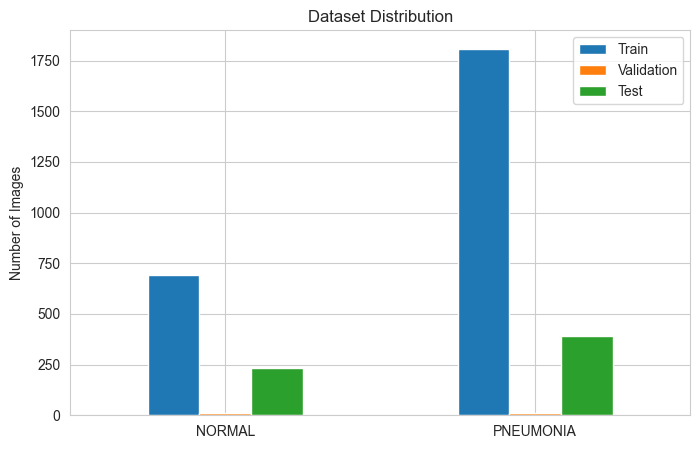

In [9]:
summary[["Train", "Validation", "Test"]].plot(
    kind="bar",
    figsize=(8,5),
    rot=0
)

plt.title("Dataset Distribution")

plt.ylabel("Number of Images")

plt.show()

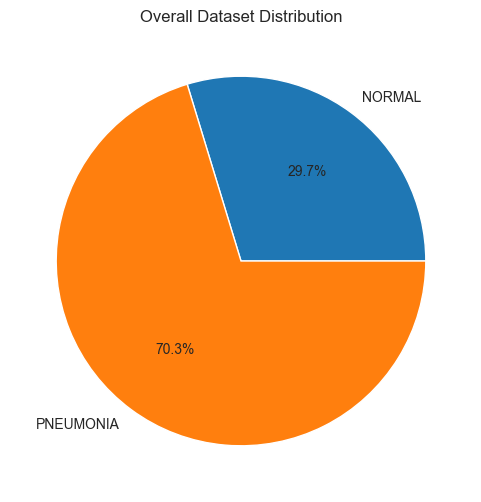

In [10]:
summary["Total"].plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6,6)
)

plt.ylabel("")

plt.title("Overall Dataset Distribution")

plt.show()

In [11]:
# Display Random Images

def show_random_images(folder, class_name, n=5):

    image_paths = list((folder / class_name).glob("*"))

    random_images = random.sample(image_paths, n)

    plt.figure(figsize=(15,3))

    for i, img_path in enumerate(random_images):

        img = Image.open(img_path)

        plt.subplot(1, n, i + 1)

        plt.imshow(img, cmap="gray")

        plt.title(class_name)

        plt.axis("off")

    plt.tight_layout()

    plt.show()

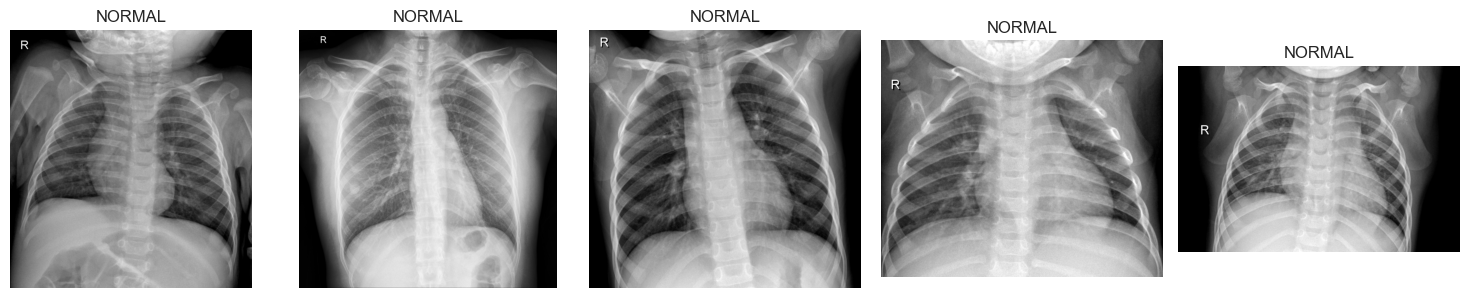

In [12]:
show_random_images(TRAIN_DIR, "NORMAL")

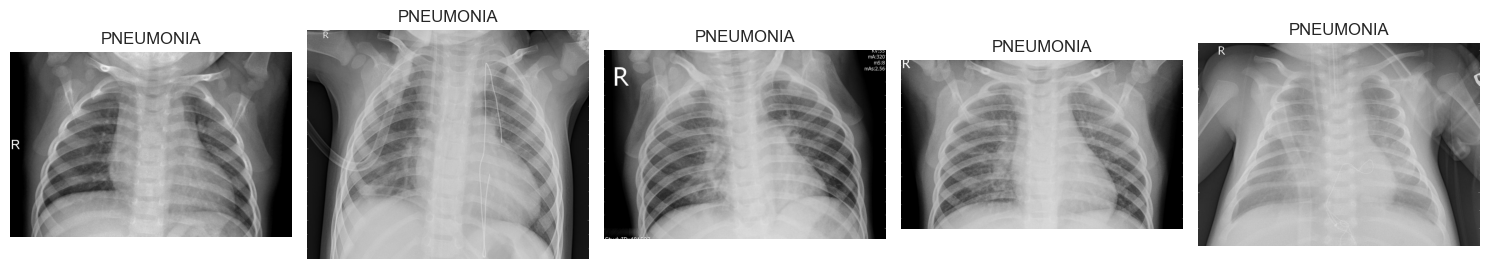

In [13]:
show_random_images(TRAIN_DIR, "PNEUMONIA")

In [14]:
def image_sizes(folder):

    sizes = []
    for class_name in os.listdir(folder):
        class_folder = folder / class_name
        if class_folder.is_dir():

            for image_path in class_folder.glob("*"):
                try:
                    img = Image.open(image_path)
                    sizes.append(img.size)

                except:
                    pass
    return sizes

In [15]:
sizes = image_sizes(TRAIN_DIR)

len(sizes)

2499

In [16]:
sizes[:10]

[(1688, 1542),
 (1782, 1310),
 (1654, 1441),
 (1774, 1225),
 (1284, 1013),
 (1622, 1422),
 (1574, 1043),
 (1454, 978),
 (1434, 1179),
 (1650, 1341)]

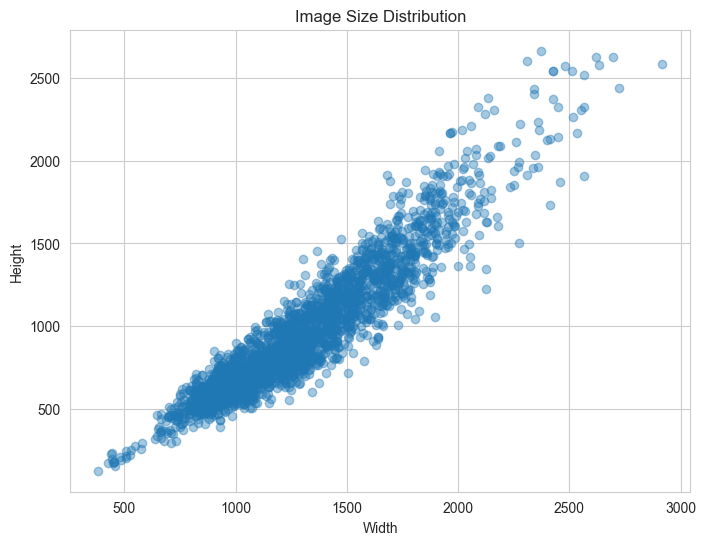

In [17]:
widths = [s[0] for s in sizes]

heights = [s[1] for s in sizes]

plt.figure(figsize=(8,6))

plt.scatter(widths, heights, alpha=0.4)

plt.xlabel("Width")

plt.ylabel("Height")

plt.title("Image Size Distribution")

plt.show()

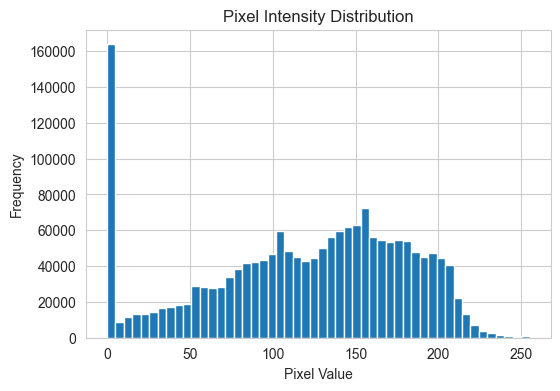

In [18]:
sample = Image.open(random.choice(list((TRAIN_DIR / "NORMAL").glob("*"))))

sample = sample.convert("L")

sample = np.array(sample)

plt.figure(figsize=(6,4))

plt.hist(sample.flatten(), bins=50)

plt.title("Pixel Intensity Distribution")

plt.xlabel("Pixel Value")

plt.ylabel("Frequency")

plt.show()